In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

In [4]:
import seaborn as sns

In [5]:
df = pd.read_csv(r"C:\Users\LENOVO\Downloads\house-prices-advanced-regression-techniques\train.csv")
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [7]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0].sort_values(ascending=False)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

In [8]:
df_model = df.copy()

In [9]:
df_model.isnull().sum()[df_model.isnull().sum() > 0]


LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64

In [10]:
categorical_none = [
    'Alley',
    'MasVnrType',
    'BsmtQual',
    'BsmtCond',
    'BsmtExposure',
    'BsmtFinType1',
    'BsmtFinType2',
    'FireplaceQu',
    'GarageType',
    'GarageFinish',
    'GarageQual',
    'GarageCond',
    'PoolQC',
    'Fence',
    'MiscFeature'
]

df_model[categorical_none] = df_model[categorical_none].fillna('None')

In [11]:
df_model['LotFrontage'] = df_model['LotFrontage'].fillna(
    df_model['LotFrontage'].median())

In [12]:
df_model['MasVnrArea'] = df_model['MasVnrArea'].fillna(0)

In [13]:
df_model['GarageYrBlt'] = df_model['GarageYrBlt'].fillna(0)

In [14]:
df_model['Electrical'] = df_model['Electrical'].fillna(
    df_model['Electrical'].mode()[0]
)

In [15]:
df_model.isnull().sum()[df_model.isnull().sum() > 0]

Series([], dtype: int64)

In [16]:
df_model['SalePrice'].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

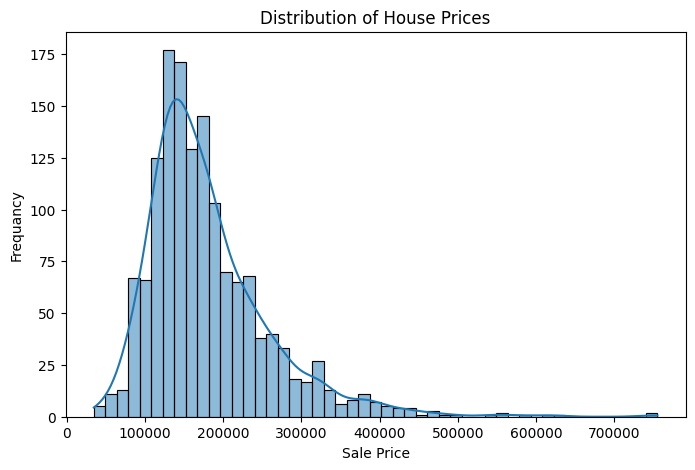

In [17]:
plt.figure(figsize=(8, 5))
sns.histplot(df_model['SalePrice'], kde=True)

plt.title('Distribution of House Prices')
plt.xlabel('Sale Price')
plt.ylabel('Frequancy')
plt.show()

In [18]:
correlation = df_model.corr(numeric_only=True)

correlation['SalePrice'].sort_values(ascending=False)

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
MasVnrArea       0.472614
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.334771
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
GarageYrBlt      0.261366
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

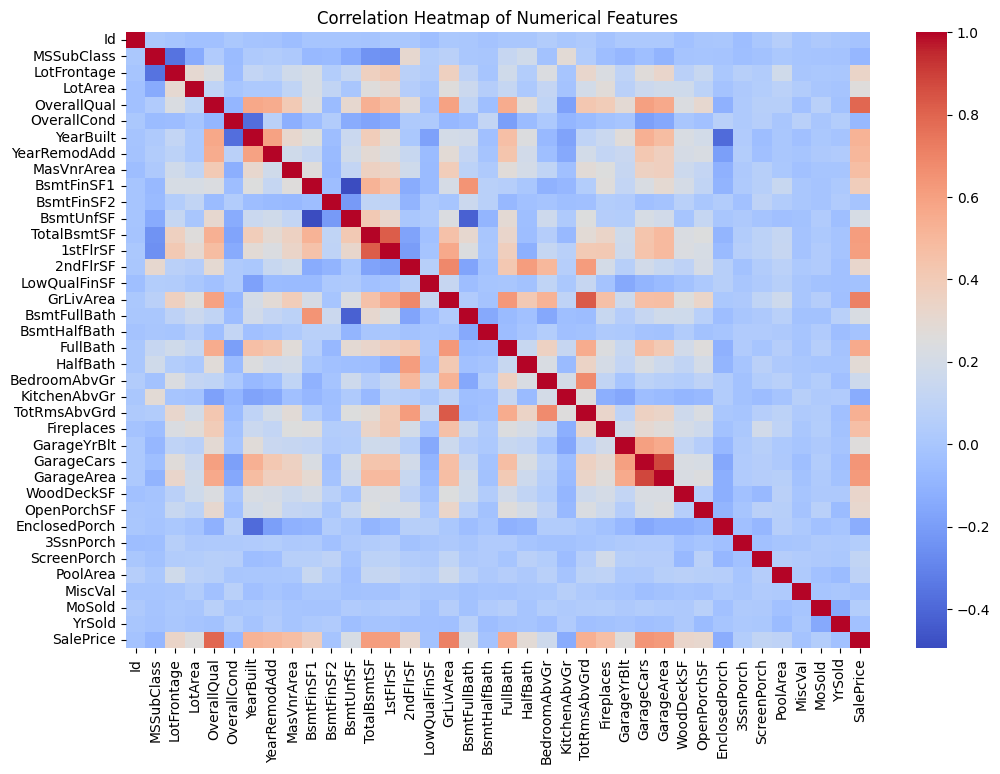

In [19]:
plt.figure(figsize=(12, 8))

sns.heatmap(correlation, cmap='coolwarm', annot=False)

plt.title('Correlation Heatmap of Numerical Features')
plt.show()

In [20]:
selected_features = [
    'OverallQual',
    'GrLivArea',
    'GarageCars',
    'GarageArea',
    'TotalBsmtSF',
    '1stFlrSF',
    'FullBath',
    'YearBuilt',
    'SalePrice'
]

df_model[selected_features].head()

,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,FullBath,YearBuilt,SalePrice
0,7,1710,2,548,856,856,2,2003,208500
1,6,1262,2,460,1262,1262,2,1976,181500
2,7,1786,2,608,920,920,2,2001,223500
3,7,1717,3,642,756,961,1,1915,140000
4,8,2198,3,836,1145,1145,2,2000,250000


### Feature Selection

Based on correlation analysis, the following eight numerical features were initially selected to predict house prices:

1. **OverallQual:** Represents the overall quality of the house.
2. **GrLivArea:** Indicates the above-ground living area.
3. **GarageCars:** Represents the garage capacity in terms of cars.
4. **GarageArea:** Indicates the total garage area.
5. **TotalBsmtSF:** Represents the total basement area.
6. **1stFlrSF:** Indicates the first-floor area.
7. **FullBath:** Represents the number of full bathrooms.
8. **YearBuilt:** Indicates the year in which the house was constructed.

These features were selected because they showed relatively strong correlations with SalePrice.

**Final Model Features:**

For the final prediction model, all 79 predictor features (numerical and categorical) were included. The categorical features were converted into numerical format using One-Hot Encoding.

The `Id` column was excluded because it is only an identification field and does not provide meaningful predictive information.

In [21]:
X = df_model.drop(['SalePrice', 'Id'], axis=1)

y = df_model['SalePrice']

In [22]:
categorical_cols = X.select_dtypes(include='object').columns

categorical_cols

Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual',
       'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual',
       'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature',
       'SaleType', 'SaleCondition'],
      dtype='object')

In [23]:
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns

numerical_cols

Index(['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond',
       'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
       'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
       'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
       'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces',
       'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF',
       'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal',
       'MoSold', 'YrSold'],
      dtype='object')

In [24]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1168, 79)
Testing Data: (292, 79)


In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [27]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ('num', 'passthrough', numerical_cols)
    ]
)

In [28]:
X_train_encoded = preprocessor.fit_transform(X_train)

X_test_encoded = preprocessor.transform(X_test)

In [29]:
print("Training Data Shape:", X_train_encoded.shape)
print("Testing Data Shape:", X_test_encoded.shape)

Training Data Shape: (1168, 300)
Testing Data Shape: (292, 300)


In [30]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train_encoded, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](300,)","[-4233.1 , 5723.64, 230.47,..., -0.06, -175.76, -175.15]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-3.024e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,300


In [31]:
y_pred = model.predict(X_test_encoded)

In [32]:
y_pred[:10]

array([157700.32129156, 350224.21490363,  92042.8875332 , 181177.2511915 ,
       341715.00390506,  66403.52238616, 249130.30376138, 152997.3338951 ,
        63483.5423701 , 149489.85021745])

In [33]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MSE: 965597173.7638605
RMSE: 31074.059499264986
R2 Score: 0.8741126325423954


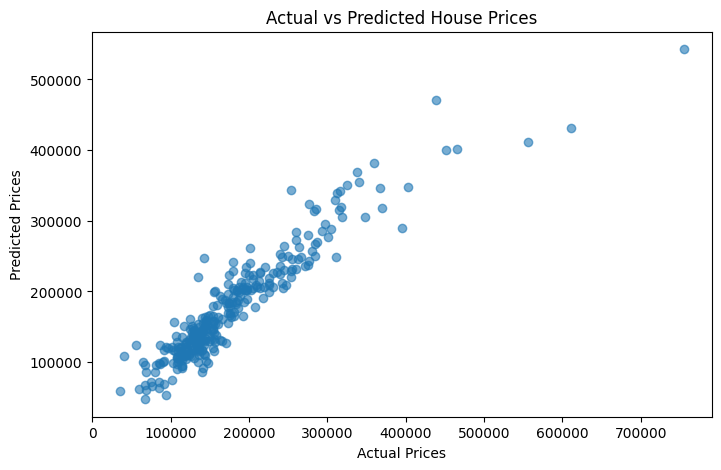

In [34]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.title('Actual vs Predicted House Prices')

plt.show()

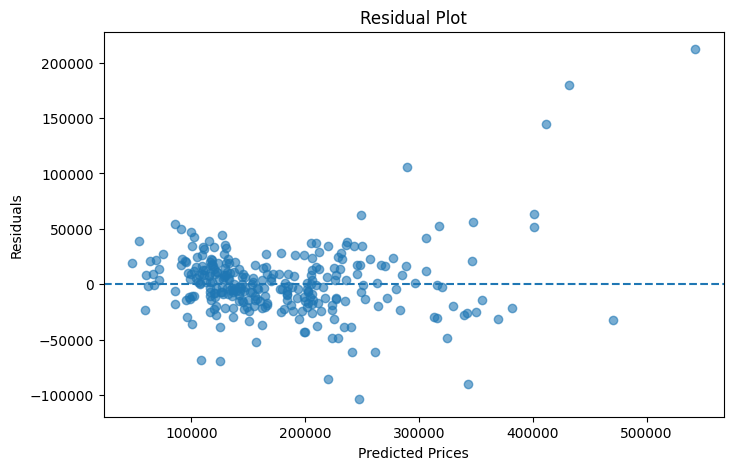

In [35]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.6)

plt.axhline(y=0, linestyle='--')

plt.xlabel('Predicted Prices')
plt.ylabel('Residuals')
plt.title('Residual Plot')

plt.show()

In [36]:
coefficients = pd.DataFrame({
    'Feature': preprocessor.get_feature_names_out(),
    'Coefficient': model.coef_
})

coefficients.sort_values(
    by='Coefficient',
    ascending=False
)

,Feature,Coefficient
43,cat__Neighborhood_NoRidge,38147.235271
50,cat__Neighborhood_StoneBr,33327.169624
44,cat__Neighborhood_NridgHt,23327.585179
99,cat__Exterior1st_BrkFace,22033.254689
146,cat__BsmtQual_Ex,20558.753093
...,...,...
66,cat__Condition2_PosN,-21167.521654
39,cat__Neighborhood_Mitchel,-21188.183468
237,cat__PoolQC_Gd,-21222.840271
14,cat__LandContour_Bnk,-21874.287496


In [37]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ridge_model = make_pipeline(
    StandardScaler(with_mean=False),
    Ridge(alpha=1.0)
)

ridge_model.fit(X_train_encoded, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,300
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](300,)","[ 0. , 0.05, 0.01,..., 51.27, 6.36,2007.82]"


In [38]:
ridge_pred = ridge_model.predict(X_test_encoded)

In [39]:
ridge_mse = mean_squared_error(y_test, ridge_pred)

ridge_rmse = np.sqrt(ridge_mse)

ridge_r2 = r2_score(y_test, ridge_pred)

print("Ridge MSE:", ridge_mse)
print("Ridge RMSE:", ridge_rmse)
print("Ridge R2 Score:", ridge_r2)

Ridge MSE: 883964425.4303036
Ridge RMSE: 29731.539237488254
Ridge R2 Score: 0.8847553022449


In [40]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge Regression'],
    'MSE': [mse, ridge_mse],
    'RMSE': [rmse, ridge_rmse],
    'R2 Score': [r2, ridge_r2]
})

comparison

,Model,MSE,RMSE,R2 Score
0,Linear Regression,9.655972e+08,31074.059499,0.874113
1,Ridge Regression,8.839644e+08,29731.539237,0.884755


--------------------Markdown----------------------

Final Observations and Conclusion

1. Linear Regression Results

     MSE: 965,597,173.76

     RMSE: ₹31,074.06

     R² Score: 0.8741

     The Linear Regression model explains approximately 87.41% of the variation in house prices.

2. Ridge Regression Results

     MSE: 883,964,425.43

     RMSE: ₹29,731.54

     R² Score: 0.8848

     The Ridge Regression model explains approximately 88.48% of the variation in house prices.

3. Model Comparison

    Ridge Regression performed better than Linear Regression on the test dataset. It achieved a lower MSE and RMSE and a higher R² score.

 ---------------------Markdown-------------------

4. Key Findings

    OverallQual and GrLivArea showed strong positive correlations with SalePrice.

    Categorical features were converted into numerical values using One-Hot Encoding.

    The Actual vs Predicted plot showed a strong relationship between actual and predicted prices.

    The Residual Plot indicated larger prediction errors for some expensive houses.

5. Conclusion

    This project used Exploratory Data Analysis, data preprocessing, One-Hot Encoding and Linear Regression to predict house prices.

    Ridge Regression achieved the best performance, with an R² score of 0.8848 and an RMSE of approximately ₹29,731.54.

    results demonstrate that combining numerical and categorical features can improve house price prediction.